<a href="https://colab.research.google.com/github/delowar-miah/Data-store-and-Retrive-from-RealTime-FirebaseDatabase/blob/master/class_4_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH=Path("/content/workplace_eda_training_dataset.csv")
CHARTS_DIR=Path("charts")
CHARTS_DIR.mkdir(exist_ok=True)


df=pd.read_csv(DATA_PATH)
print("Dataset shape:",df.shape)
df.head(10)



Dataset shape: (720, 16)


,learner_record_id,region,department,role_family,experience_band,training_mode,prior_python_score,course_minutes,manager_support_score,support_tickets_last_30d,engagement_score,completion_days,assessment_score,satisfaction_score,productivity_gain_estimate_pct,completed_training
0,EDA-0001,Wales,HR,Administrator,6-10 years,Blended,39.4,389.0,3,1,74.2,20.0,79.4,4.7,11.5,1
1,EDA-0002,Scotland,Customer Support,Developer,3-5 years,Self-paced,47.7,256.0,3,1,83.2,11.0,84.9,4.5,11.1,1
2,EDA-0003,Yorkshire,Customer Support,Developer,0-2 years,Instructor-led,51.1,397.0,4,0,100.0,22.0,91.7,5.0,12.3,1
3,EDA-0004,South East,HR,Advisor,10+ years,Instructor-led,49.9,272.0,3,0,86.7,14.0,81.9,4.1,9.8,1
4,EDA-0005,North West,Finance,Administrator,0-2 years,Blended,40.7,379.0,5,1,89.9,13.0,95.9,4.8,13.1,1
5,EDA-0006,West Midlands,Operations,Administrator,6-10 years,Blended,72.1,434.0,3,1,98.8,9.0,100.0,5.0,12.7,1
6,EDA-0007,North West,Customer Support,Advisor,0-2 years,Self-paced,41.3,257.0,5,4,83.2,30.0,73.4,4.7,14.8,1
7,EDA-0008,Yorkshire,Sales,Coordinator,3-5 years,Instructor-led,50.0,344.0,3,2,70.5,13.0,90.7,4.4,8.3,1
8,EDA-0009,London,Finance,Administrator,3-5 years,Instructor-led,51.7,392.0,2,2,81.7,26.0,86.0,4.0,14.7,1
9,EDA-0010,London,Customer Support,Analyst,0-2 years,Self-paced,78.7,341.0,4,0,78.0,5.0,93.2,4.4,13.8,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   learner_record_id               720 non-null    object 
 1   region                          720 non-null    object 
 2   department                      720 non-null    object 
 3   role_family                     720 non-null    object 
 4   experience_band                 720 non-null    object 
 5   training_mode                   720 non-null    object 
 6   prior_python_score              720 non-null    float64
 7   course_minutes                  720 non-null    float64
 8   manager_support_score           720 non-null    int64  
 9   support_tickets_last_30d        720 non-null    int64  
 10  engagement_score                720 non-null    float64
 11  completion_days                 720 non-null    float64
 12  assessment_score                720 

In [13]:
target_rate=df["completed_training"].mean()
print(f"Completion rate:{target_rate:.1%}")
df["completed_training"].value_counts(normalize=True).rename("Proportion")

Completion rate:87.5%


,Proportion
completed_training,
1,0.875
0,0.125


In [14]:

# Calculate the average training completion rate
target_rate = df["completed_training"].mean()

# Display completion rate as a percentage
print(f"Completion rate: {target_rate:.1%}")

# Display the proportion of completed and incomplete training
df["completed_training"].value_counts(
    normalize=True
).rename("Proportion")


Completion rate: 87.5%


,Proportion
completed_training,
1,0.875
0,0.125


Descriptive statistics summarise centre, spread, and range. They do not explain causality, but they help identify where to investigate.

In [15]:

# Step 1: Define numerical columns
numeric_cols = [
    "prior_python_score",
    "course_minutes",
    "manager_support_score",
    "support_tickets_last_30d",
    "engagement_score",
    "completion_days",
    "assessment_score",
    "satisfaction_score",
    "productivity_gain_estimate_pct"
]

# Step 2: Select numerical columns
numeric_data = df[numeric_cols]

# Step 3: Calculate descriptive statistics
statistics = numeric_data.describe()

# Step 4: Transpose rows and columns
statistics = statistics.T

# Step 5: Round results to two decimal places
statistics = statistics.round(2)

# Step 6: Display results
display(statistics)


,count,mean,std,min,25%,50%,75%,max
prior_python_score,720.0,54.26,17.07,5.0,41.98,54.4,65.80,98.0
course_minutes,720.0,362.76,84.94,111.0,302.00,363.0,421.00,620.0
manager_support_score,720.0,3.27,1.15,1.0,3.00,3.0,4.00,5.0
support_tickets_last_30d,720.0,1.17,1.15,0.0,0.00,1.0,2.00,8.0
engagement_score,720.0,78.15,13.33,27.5,69.38,78.7,88.60,100.0
completion_days,720.0,18.98,7.52,3.0,14.00,19.0,24.00,41.0
assessment_score,720.0,82.41,10.58,37.3,75.57,82.2,90.12,100.0
satisfaction_score,720.0,4.55,0.52,2.1,4.28,4.7,5.00,5.0
productivity_gain_estimate_pct,720.0,11.32,2.83,0.8,9.70,11.3,13.20,18.0


Now Calculate cetegorical columns

In [16]:

# Step 1: Create a list of categorical columns
categorical_cols = [
    "region",
    "department",
    "role_family",
    "experience_band",
    "training_mode"
]

# Step 2: Loop through each column
for col in categorical_cols:

    # Step 3: Print the column name
    print(f"\n{col}")

    # Step 4: Count each category
    # Step 5: Display the top 10 categories
    print(df[col].value_counts().head(10))



region
region
London           118
Yorkshire        116
Wales            106
South East       105
Scotland         100
North West        91
West Midlands     84
Name: count, dtype: int64

department
department
Sales               129
Operations          122
Customer Support    110
IT                  109
Product              90
HR                   85
Finance              75
Name: count, dtype: int64

role_family
role_family
Coordinator      134
Analyst          127
Developer        122
Administrator    118
Advisor          110
Manager          109
Name: count, dtype: int64

experience_band
experience_band
3-5 years     238
6-10 years    215
0-2 years     154
10+ years     113
Name: count, dtype: int64

training_mode
training_mode
Self-paced        271
Blended           266
Instructor-led    183
Name: count, dtype: int64


In [17]:
df[col].isna().sum()

np.int64(0)

3. Plot 1: Distribution of assessment score

Question: are assessment scores concentrated, spread out, skewed, or separated by completion status?

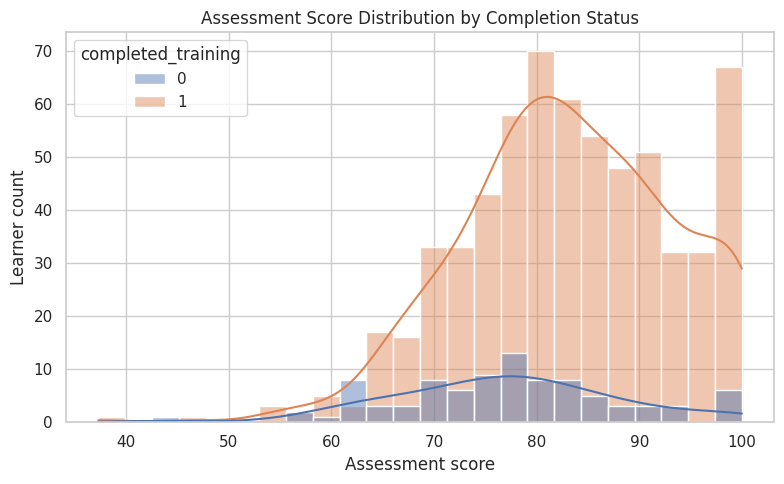

Observation: completers tend to have a higher assessment-score distribution.
Modelling implication: assessment_score may be predictive, but check whether it is available before prediction time.


In [18]:

# Create a figure with width 8 inches and height 5 inches
plt.figure(figsize=(8, 5))

# Create a histogram of assessment scores
sns.histplot(
    data=df,                     # Dataset
    x="assessment_score",        # X-axis variable
    hue="completed_training",    # Compare completion groups by colour
    bins=24,                     # Number of intervals
    kde=True,                    # Add smooth density curves
    alpha=0.45                   # Set bar transparency
)

# Add the chart title
plt.title("Assessment Score Distribution by Completion Status")

# Label the X-axis
plt.xlabel("Assessment score")

# Label the Y-axis
plt.ylabel("Learner count")

# Adjust spacing
plt.tight_layout()

# Save the chart as a PNG image
plt.savefig(
    CHARTS_DIR / "01_distribution_assessment_score.png",
    dpi=180
)

# Display the chart
plt.show()

# Print the observation
print(
    "Observation: completers tend to have a higher "
    "assessment-score distribution."
)

# Print the modelling implication
print(
    "Modelling implication: assessment_score may be "
    "predictive, but check whether it is available "
    "before prediction time."
)


Plot 2: Completion rate by training mode

Question: does completion differ by training mode?

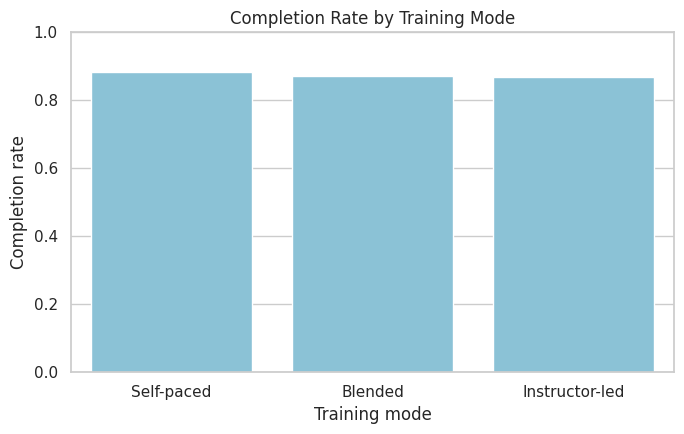

    training_mode  completed_training
0      Self-paced            0.881919
1         Blended            0.872180
2  Instructor-led            0.868852


In [19]:

# Group employees by training mode
completion_by_mode = (
    df.groupby("training_mode")["completed_training"]

    # Calculate completion rate for each mode
    .mean()

    # Sort from highest to lowest completion rate
    .sort_values(ascending=False)

    # Convert the result into a regular DataFrame
    .reset_index()
)
plt.figure(figsize=(7, 4.5))
sns.barplot(data=completion_by_mode, x="training_mode", y="completed_training", color="#7EC8E3")
plt.title("Completion Rate by Training Mode")
plt.xlabel("Training mode")
plt.ylabel("Completion rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "02_completion_by_training_mode.png", dpi=180)
plt.show()
# Display the result
print(completion_by_mode)


5. Plot 3: Correlation heatmap

Question: which numerical variables move together? Correlation does not prove causation, but it suggests relationships worth testing.

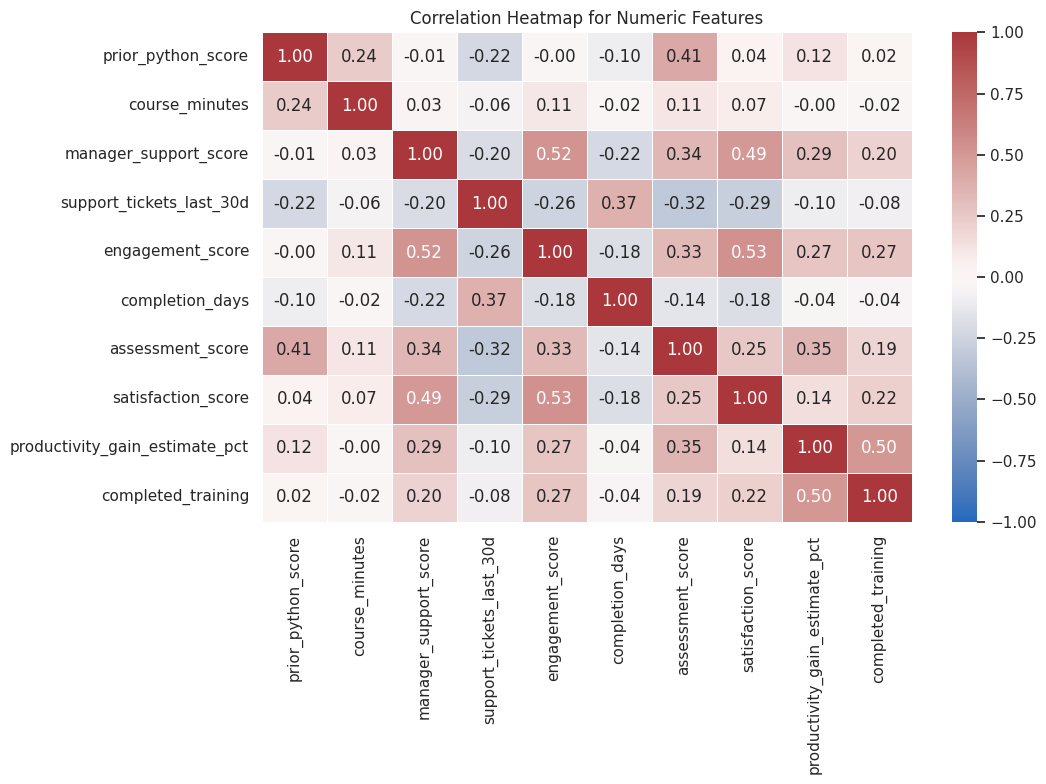

In [20]:

# Select numerical features and target
corr_cols = numeric_cols + ["completed_training"]

# Calculate correlation matrix
correlation_matrix = df[corr_cols].corr(numeric_only=True)

# Create figure
plt.figure(figsize=(11, 8))

# Create correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,       # Display correlation values
    fmt=".2f",        # Show two decimal places
    cmap="vlag",      # Colour palette
    center=0,         # Centre colour scale at zero
    vmin=-1,          # Minimum correlation value
    vmax=1,           # Maximum correlation value
    linewidths=0.4    # Add lines between cells
)

# Add title
plt.title("Correlation Heatmap for Numeric Features")

# Adjust layout
plt.tight_layout()

# Save the chart
plt.savefig(
    CHARTS_DIR / "03_correlation_heatmap.png",
    dpi=180
)

# Display the chart
plt.show()


Plot 4: Feature-target relationship

Question: is engagement different for learners who completed training versus those who did not?


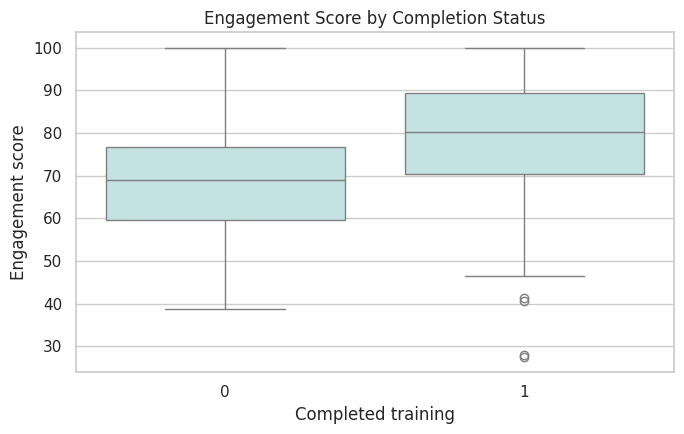

Observation: completers generally show higher engagement scores.
Modelling implication: engagement_score may be useful, but timing matters. If measured after completion, it could leak outcome information.


In [21]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="completed_training", y="engagement_score", color="#BFE7E7")
plt.title("Engagement Score by Completion Status")
plt.xlabel("Completed training")
plt.ylabel("Engagement score")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "04_engagement_vs_completion.png", dpi=180)
plt.show()

print("Observation: completers generally show higher engagement scores.")
print("Modelling implication: engagement_score may be useful, but timing matters. If measured after completion, it could leak outcome information.")

Plot 5: Stakeholder-facing chart

Question: what message would a learning manager need to hear?

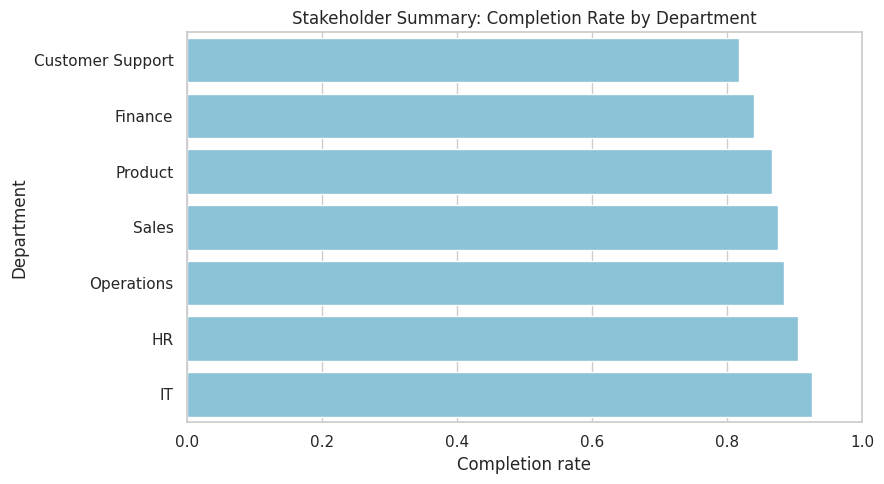

,department,completion_rate,avg_engagement,records
0,Customer Support,0.818182,77.055455,110
1,Finance,0.840000,77.292000,75
2,Product,0.866667,78.428889,90
3,Sales,0.875969,80.296124,129
4,Operations,0.885246,78.961475,122
5,HR,0.905882,75.956471,85
6,IT,0.926606,77.859633,109


In [22]:
summary = (
    df.groupby("department")
      .agg(completion_rate=("completed_training", "mean"),
           avg_engagement=("engagement_score", "mean"),
           records=("learner_record_id", "count"))
      .sort_values("completion_rate", ascending=True)
      .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=summary, x="completion_rate", y="department", color="#7EC8E3")
plt.title("Stakeholder Summary: Completion Rate by Department")
plt.xlabel("Completion rate")
plt.ylabel("Department")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "05_stakeholder_completion_by_department.png", dpi=180)
plt.show()

summary

Convert charts into modelling hypotheses

Complete the statements below after reviewing your charts.


In [23]:
hypotheses = [
    "H1: engagement_score may help predict completed_training because completers show higher engagement.",
    "H2: training_mode may help because completion rates differ by delivery format.",
    "H3: support_tickets_last_30d may indicate friction and may be negatively related to completion.",
    "Leakage caveat: assessment_score and productivity_gain_estimate_pct may not be available before the prediction decision."
]
for h in hypotheses:
    print("-", h)

- H1: engagement_score may help predict completed_training because completers show higher engagement.
- H2: training_mode may help because completion rates differ by delivery format.
- H3: support_tickets_last_30d may indicate friction and may be negatively related to completion.
- Leakage caveat: assessment_score and productivity_gain_estimate_pct may not be available before the prediction decision.


Create one additional chart of your choice. It must include:

1. A clear question.
2. A chart title and axis labels.
3. One written observation.
4. One modelling implication.
5. One caveat about bias, leakage, sample size, or timing.

Student exercise starter cell
Replace the column names and chart type if you want to explore a different question.

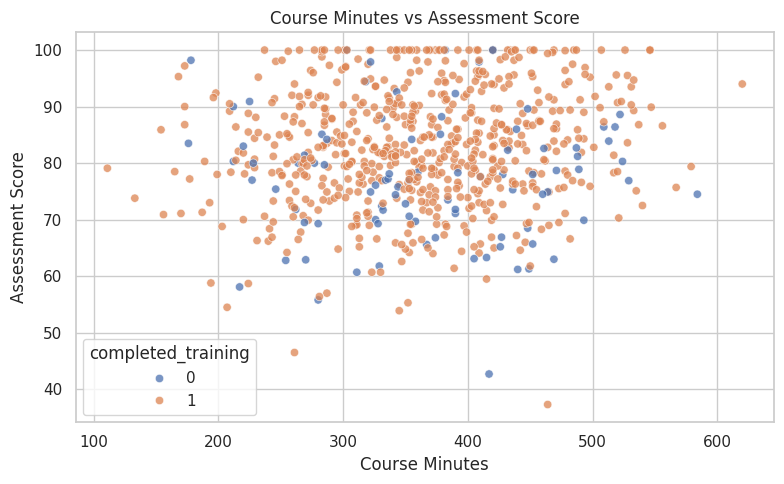

Observation: The scatterplot helps identify whether longer courses are associated with higher or lower assessment scores and whether completion groups differ.
Modelling implication: Course duration may be a useful predictor of training completion if the groups show different patterns.
Caveat: Assessment scores may only be available after training, creating potential data leakage if used to predict completion beforehand.


In [26]:
# Research Question:
# Does course duration relate to assessment scores,
# and does this differ by training completion status?


plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="course_minutes",
    y="assessment_score",
    hue="completed_training",
    alpha=0.75
)

plt.title("Course Minutes vs Assessment Score")
plt.xlabel("Course Minutes")
plt.ylabel("Assessment Score")

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "student_exercise_chart.png",
    dpi=180
)

plt.show()

# Observation
print("Observation: The scatterplot helps identify whether longer courses are associated with higher or lower assessment scores and whether completion groups differ.")
# Modelling implication
print("Modelling implication: Course duration may be a useful predictor of training completion if the groups show different patterns.")

# Caveat
print("Caveat: Assessment scores may only be available after training, creating potential data leakage if used to predict completion beforehand.")

#Observation
The scatterplot allows us to examine whether course duration is associated with assessment scores. It also helps identify whether employees who completed training have different score distributions from those who did not.

#Modelling implication
Course duration could be considered as an input feature for a classification model predicting training completion. If completion groups show distinct patterns, course_minutes may provide useful predictive information.

#Caveat: Data leakage
Assessment scores may not be available until employees finish their training. Using these scores to predict completion at an earlier stage could introduce data leakage and make the model's performance appear better than it actually is.